# 01 — Data Exploration & Dataset Acquisition

This notebook verifies the PyTorch/CUDA setup and downloads/filters the datasets for **Timeguessr AI**:
1. **Local Timeguessr daily challenges** (`data/images/Timeguessr/`)
2. **OSV-5M** ([`osv5m/osv5m`](https://huggingface.co/datasets/osv5m/osv5m)) — global street-view geolocation images (lat/lon + admin labels; *note: no capture year*)
3. **PastVu** ([`nyuuzyou/pastvu`](https://huggingface.co/datasets/nyuuzyou/pastvu)) — historical geotagged & year-labeled photographs (1826–2000)
4. **YFCC15M** ([`mehdidc/yfcc15m`](https://huggingface.co/datasets/mehdidc/yfcc15m)) — filtered strictly for **valid geolocation** and **valid capture date**, plus concurrent image downloading
5. **Wikimedia Commons** (MediaWiki Action API) — modern (**2015–2026**) geotagged, timestamped non-Street-View photography (cityscapes, landscapes, streets, landmarks) to eliminate the OSV-5M temporal domain shift

In [1]:
import torch

print(f"PyTorch: {torch.__version__} | CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

PyTorch: 2.11.0+cu128 | CUDA available: True
Device: NVIDIA GeForce RTX 4070 SUPER
VRAM: 12.88 GB


## 0. Configuration & Directories

These datasets are very large at full scale (OSV-5M is ~250 GB, PastVu is ~2M images across 2,094 tar shards, and YFCC15M's metadata CSV alone is ~10 GB). Adjust the limits below to start with a manageable subset or set them to `None` to download everything.

> **Optional:** If you hit Hugging Face rate limits, set your `HF_TOKEN` in a `.env` file or call `huggingface_hub.login()`.

In [10]:
import os
from pathlib import Path
from dotenv import load_dotenv
from huggingface_hub import login, get_token, whoami

load_dotenv()

# --- Hugging Face Authentication (raises Hub/resolver rate limits) ---
hf_token = os.getenv("HF_TOKEN")
if hf_token:
    login(token=hf_token, add_to_git_credential=False)
    print(f"Authenticated with Hugging Face as: {whoami()['name']}")
elif get_token():
    print(f"Authenticated with cached HF token as: {whoami()['name']}")
else:
    print("Not authenticated with Hugging Face (using lower anonymous rate limits).")
    print("Set HF_TOKEN in .env or uncomment login() below to authenticate interactively:")
    # login()

# Base data directory
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
IMAGES_DIR = DATA_DIR / "images"

OSV5M_DIR = IMAGES_DIR / "osv5m"
PASTVU_DIR = IMAGES_DIR / "pastvu"
YFCC_DIR = IMAGES_DIR / "yfcc15m"
WIKIMEDIA_DIR = IMAGES_DIR / "wikimedia"
TIMEGUESSR_DIR = IMAGES_DIR / "Timeguessr"

for d in (OSV5M_DIR, PASTVU_DIR, YFCC_DIR, WIKIMEDIA_DIR):
    d.mkdir(parents=True, exist_ok=True)

# --- Global Year Bounds (Timeguessr range) ---
MIN_YEAR = 1900
MAX_YEAR = 2026

# PastVu: number of valid (1900-2026, geotagged) images to stream and save
PASTVU_MAX_SAMPLES = 50_000  # None = all valid images (1900-2026, geotagged)

# --- Balanced Sampling Controls ---
# alpha = 0.0 -> strictly uniform | 0.5 -> square-root (sublinear) | 1.0 -> raw distribution
OSV5M_TARGET_SAMPLES = 50_000
OSV5M_COUNTRY_ALPHA = 0.6
OSV5M_MAX_PER_SEQUENCE = 2
OSV5M_MAX_ZIPS = 33          # More shards = better coverage of rare countries (set None for all 98)

# YFCC15M: number of valid (geotagged + valid date) rows to collect, and how many images to fetch
YFCC_MIN_GEO_ACCURACY = 11        # Flickr accuracy: 1=world, 3=country, 6=region, 11=city, 16=street
YFCC_DOWNLOAD_WORKERS = 16
YFCC_TARGET_IMAGES = 50_000
YFCC_COUNTRY_ALPHA = 0.6
YFCC_MAX_VALID_SCAN = 200_000     # Valid metadata rows to stream before sublinear selection
YFCC_OVERSAMPLE_FACTOR = 1.8      # Extra metadata per bucket to survive dead Flickr URLs
YFCC_GEOCODE_BATCH_SIZE = 4_000

# Wikimedia Commons: modern (2015-2026) geotagged non-Street-View photos
WIKIMEDIA_MIN_YEAR = 2015
WIKIMEDIA_MAX_YEAR = 2026
WIKIMEDIA_TARGET_IMAGES = 15_000
WIKIMEDIA_COUNTRY_ALPHA = 0.6
WIKIMEDIA_DOWNLOAD_WORKERS = 3    # Wikimedia guideline: keep CDN concurrency <= 3
WIKIMEDIA_USER_AGENT = "TimeguessrAI-CS441/1.0 (https://github.com/cbeve2/CS441; cbeve2@illinois.edu)"

print(f"Project root: {PROJECT_ROOT}")
print(f"Data dir:     {DATA_DIR}")

Authenticated with cached HF token as: darksabre1500
Project root: d:\VSCodeProjects\CS441
Data dir:     d:\VSCodeProjects\CS441\data


## 1. Download `osv5m/osv5m` (OpenStreetView-5M)

- Uses `huggingface_hub` directly (compatible with `datasets >= 4.0` where legacy dataset loading scripts are disabled).
- Computes **sublinear country quotas** ($q_c \propto n_c^\alpha$) and **water-filled year quotas** using `captured_at` (2011–2022) from `train.csv`, plus sequence deduplication (`OSV5M_MAX_PER_SEQUENCE`).
- Selectively extracts only the images needed to fill open `(country, year)` buckets, checkpoints after every `.zip` shard, and can be safely interrupted and resumed at any time.

In [3]:
import pandas as pd

def allocate_sublinear_quotas(counts: dict, total_target: int, alpha: float = 0.5) -> dict:
    """Allocate `total_target` items across keys with weights proportional to count**alpha,
    capped at each key's available count (water-filling redistribution)."""
    avail = {k: int(v) for k, v in counts.items() if v > 0}
    if not avail or total_target <= 0:
        return {}
    if sum(avail.values()) <= total_target:
        return avail.copy()

    quotas = {k: 0 for k in avail}
    remaining = total_target
    active = dict(avail)

    while remaining > 0 and active:
        weights = {k: (v ** alpha) for k, v in active.items()}
        w_sum = sum(weights.values())
        allocated_this_round = 0
        saturated = []

        for k, cap in active.items():
            share = int(remaining * (weights[k] / w_sum))
            add = min(share, cap - quotas[k])
            quotas[k] += add
            allocated_this_round += add
            if quotas[k] >= cap:
                saturated.append(k)

        remaining -= allocated_this_round
        for k in saturated:
            active.pop(k, None)

        # Distribute rounding remainder 1-by-1 to highest-weight unsaturated keys
        if allocated_this_round == 0 and remaining > 0 and active:
            for k in sorted(active, key=lambda x: active[x] ** alpha, reverse=True):
                if remaining == 0:
                    break
                if quotas[k] < active[k]:
                    quotas[k] += 1
                    remaining -= 1
            break

    return {k: q for k, q in quotas.items() if q > 0}


def build_country_year_quotas(df: pd.DataFrame, total_target: int, country_alpha: float = 0.5) -> dict[tuple[str, int], int]:
    """Sublinear across countries, then uniform (alpha=0.0) water-filling across years within each country."""
    country_counts = df["country"].value_counts().to_dict()
    country_quotas = allocate_sublinear_quotas(country_counts, total_target, alpha=country_alpha)

    cell_quotas: dict[tuple[str, int], int] = {}
    grouped = df.groupby("country")["year"].value_counts()
    for country, c_quota in country_quotas.items():
        yr_counts = grouped.loc[country].to_dict()
        yr_quotas = allocate_sublinear_quotas(yr_counts, c_quota, alpha=0.0)
        for yr, q in yr_quotas.items():
            cell_quotas[(country, int(yr))] = q
    return cell_quotas

In [8]:
import json
import zipfile
from collections import defaultdict
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from huggingface_hub import HfApi, hf_hub_download

OSV5M_REPO = "osv5m/osv5m"

def download_osv5m_balanced(
    output_dir: Path = OSV5M_DIR,
    target_samples: int = OSV5M_TARGET_SAMPLES,
    country_alpha: float = OSV5M_COUNTRY_ALPHA,
    max_per_sequence: int = OSV5M_MAX_PER_SEQUENCE,
    max_zips: int | None = OSV5M_MAX_ZIPS,
    delete_zips_after_extract: bool = False,
) -> pd.DataFrame:
    img_dir = output_dir / "images_balanced"
    img_dir.mkdir(parents=True, exist_ok=True)
    meta_out = output_dir / "metadata_balanced.csv"
    state_path = output_dir / "completed_zips.json"

    # 1. Ensure train.csv is downloaded
    train_csv = Path(
        hf_hub_download(
            repo_id=OSV5M_REPO,
            repo_type="dataset",
            filename="train.csv",
            local_dir=str(output_dir),
        )
    )

    print("Loading OSV-5M train.csv metadata...")
    cols = ["id", "latitude", "longitude", "country", "sequence", "captured_at"]
    meta_df = pd.read_csv(train_csv, usecols=cols)
    meta_df["year"] = pd.to_datetime(meta_df["captured_at"], unit="ms", errors="coerce").dt.year
    meta_df = meta_df.dropna(subset=["id", "latitude", "longitude", "country", "year"]).copy()
    meta_df["id"] = meta_df["id"].astype("int64")
    meta_df["year"] = meta_df["year"].astype("int32")
    meta_df = meta_df[(meta_df["year"] >= MIN_YEAR) & (meta_df["year"] <= MAX_YEAR)]

    # 2. Compute sublinear (country, year) quotas
    cell_quotas = build_country_year_quotas(meta_df, target_samples, country_alpha=country_alpha)
    total_quota = sum(cell_quotas.values())
    print(f"Computed quotas for {len(cell_quotas):,} (country, year) buckets across "
          f"{len({c for c, _ in cell_quotas})} countries (target={total_quota:,}).")

    # Fast lookup dict: id -> (country, year, lat, lon, sequence)
    meta_lookup = dict(
        zip(
            meta_df["id"],
            zip(meta_df["country"], meta_df["year"], meta_df["latitude"], meta_df["longitude"], meta_df["sequence"]),
        )
    )
    del meta_df

    # 3. Resume from existing checkpoint if present
    records: list[dict] = []
    seen_ids: set[int] = set()
    cell_filled: dict[tuple[str, int], int] = defaultdict(int)
    seq_counts: dict[str, int] = defaultdict(int)
    completed_zips: set[str] = set()

    if meta_out.exists():
        prev_df = pd.read_csv(meta_out)
        records = prev_df.to_dict(orient="records")
        for r in records:
            img_id = int(r["id"])
            seen_ids.add(img_id)
            cell_filled[(str(r["country"]), int(r["year"]))] += 1
            if pd.notna(r.get("sequence")):
                seq_counts[str(r["sequence"])] += 1
        print(f"Resuming OSV-5M from {len(records):,} existing records in {meta_out}")

    if state_path.exists():
        completed_zips = set(json.loads(state_path.read_text(encoding="utf-8")))
        print(f"Skipping {len(completed_zips)} already-completed zip shards.")

    # 4. Iterate over train zip shards and selectively extract needed images
    api = HfApi()
    train_zips = sorted(
        f for f in api.list_repo_files(repo_id=OSV5M_REPO, repo_type="dataset")
        if f.startswith("images/train/") and f.endswith(".zip")
    )
    if max_zips is not None:
        train_zips = train_zips[:max_zips]

    pbar = tqdm(total=total_quota, initial=len(records), desc="OSV-5M balanced images")

    try:
        for rel_zip in train_zips:
            if len(records) >= total_quota:
                break
            if rel_zip in completed_zips:
                continue

            zip_path = Path(
                hf_hub_download(
                    repo_id=OSV5M_REPO,
                    repo_type="dataset",
                    filename=rel_zip,
                    local_dir=str(output_dir),
                )
            )

            with zipfile.ZipFile(zip_path, "r") as zf:
                for member in zf.namelist():
                    if not member.lower().endswith(".jpg"):
                        continue
                    try:
                        img_id = int(Path(member).stem)
                    except ValueError:
                        continue
                    if img_id in seen_ids:
                        continue

                    info = meta_lookup.get(img_id)
                    if info is None:
                        continue

                    country, year, lat, lon, seq = info
                    key = (country, year)
                    quota = cell_quotas.get(key, 0)
                    if cell_filled[key] >= quota:
                        continue
                    if pd.notna(seq) and seq_counts[str(seq)] >= max_per_sequence:
                        continue

                    out_path = img_dir / f"{img_id}.jpg"
                    if not out_path.exists():
                        out_path.write_bytes(zf.read(member))

                    seen_ids.add(img_id)
                    cell_filled[key] += 1
                    if pd.notna(seq):
                        seq_counts[str(seq)] += 1

                    records.append({
                        "id": img_id,
                        "image_path": str(out_path.relative_to(PROJECT_ROOT)),
                        "year": year,
                        "latitude": lat,
                        "longitude": lon,
                        "country": country,
                        "sequence": seq,
                        "source": "osv5m",
                    })
                    pbar.update(1)
                    if len(records) >= total_quota:
                        break

            completed_zips.add(rel_zip)
            if delete_zips_after_extract and zip_path.exists():
                zip_path.unlink()

            # Checkpoint after every zip shard
            if records:
                pd.DataFrame(records).to_csv(meta_out, index=False)
            state_path.write_text(json.dumps(sorted(completed_zips)), encoding="utf-8")

    except KeyboardInterrupt:
        print("\nInterrupted! Saving collected OSV-5M metadata so far...")
    finally:
        pbar.close()
        out_df = pd.DataFrame(records)
        if len(out_df) > 0:
            out_df.to_csv(meta_out, index=False)
            state_path.write_text(json.dumps(sorted(completed_zips)), encoding="utf-8")
            print(f"Saved {len(out_df):,} OSV-5M samples across {out_df['country'].nunique()} countries -> {meta_out}")
        else:
            print("No OSV-5M samples collected yet.")

    return out_df

osv_balanced_df = download_osv5m_balanced()
display(osv_balanced_df.head())

Loading OSV-5M train.csv metadata...
Computed quotas for 1,587 (country, year) buckets across 219 countries (target=50,000).
Resuming OSV-5M from 41,285 existing records in d:\VSCodeProjects\CS441\data\osv5m\metadata_balanced.csv
Skipping 7 already-completed zip shards.


OSV-5M balanced images:  83%|########2 | 41285/50000 [00:00<?, ?it/s]

images/train/07.zip: reconstructing file:   0%|          |  0.00B / 2.52GB            

images/train/07.zip: downloading bytes:           |  0.00B            

images/train/08.zip: reconstructing file:   0%|          |  0.00B / 2.52GB            

images/train/08.zip: downloading bytes:           |  0.00B            

... (46 outputs left out)

images/train/32.zip: reconstructing file:   0%|          |  0.00B / 2.52GB            

images/train/32.zip: downloading bytes:           |  0.00B            

Saved 46,461 OSV-5M samples across 217 countries -> d:\VSCodeProjects\CS441\data\osv5m\metadata_balanced.csv


,id,image_path,year,latitude,longitude,country,sequence,source
0,181393113831089,data\osv5m\images_balanced\181393113831089.jpg,2015,48.458717,10.178702,DE,Gkvxsd3uzsVH3dg4iOfoTg,osv5m
1,346368943791346,data\osv5m\images_balanced\346368943791346.jpg,2021,-16.698935,-66.727658,BO,JscUefbCSqu5h82MIyaG9m,osv5m
2,148306984644239,data\osv5m\images_balanced\148306984644239.jpg,2020,48.094460,-113.974946,US,OWSiCb1RFrsZ3xn9yTq406,osv5m
3,319355266252737,data\osv5m\images_balanced\319355266252737.jpg,2018,53.128190,10.910581,DE,vm4pm9pb5c9vliizcu51zn,osv5m
4,832072764060105,data\osv5m\images_balanced\832072764060105.jpg,2016,31.993929,-111.980419,US,ME665dtjQ5eh2f8kqaq1Yw,osv5m


## 2. Download `nyuuzyou/pastvu` (PastVu Historical Photos)

- Packaged on Hugging Face in WebDataset (`.tar`) format with paired images and JSON metadata (`geo: [lat, lon]`, `year`, `year2`, `title`, etc.).
- Downloads `.tar` shards one at a time via `huggingface_hub` and reads them directly with Python's `tarfile` (avoiding `datasets` WebDataset's PyArrow schema inference, which fails on `frags[].h` mixing `int64` and `double` across shards).
- Filters to photos with valid coordinates (`-90 <= lat <= 90`, `-180 <= lon <= 180`, excluding `(0, 0)`) and `MIN_YEAR <= year <= MAX_YEAR`.
- Saves images into `data/images/pastvu/images/` and clean tabular labels into `data/images/pastvu/metadata.csv`.

In [ ]:
import json
import math
import tarfile
from io import BytesIO
import pandas as pd
from PIL import Image
from huggingface_hub import HfApi, hf_hub_download
from tqdm.auto import tqdm

PASTVU_REPO = "nyuuzyou/pastvu"
IMAGE_EXTS = {"jpg", "jpeg", "png", "webp"}

def _parse_pastvu_record(meta: dict, img_bytes: bytes, img_dir: Path, min_year: int, max_year: int, max_year_span: int) -> dict | None:
    year = meta.get("year")
    year2 = meta.get("year2")
    try:
        year = int(year)
    except (TypeError, ValueError):
        return None
    if not (min_year <= year <= max_year):
        return None
    if year2 is not None:
        try:
            year2 = int(year2)
            if abs(year2 - year) > max_year_span:
                return None
            year = round((year + year2) / 2)
        except (TypeError, ValueError):
            year2 = None

    geo = meta.get("geo")
    if not isinstance(geo, (list, tuple)) or len(geo) != 2:
        return None
    try:
        lat, lon = float(geo[0]), float(geo[1])
    except (TypeError, ValueError):
        return None
    if not (math.isfinite(lat) and math.isfinite(lon)):
        return None
    if not (-90.0 <= lat <= 90.0 and -180.0 <= lon <= 180.0) or (lat == 0.0 and lon == 0.0):
        return None

    cid = str(meta.get("cid") or "unknown")
    img_path = img_dir / f"{cid}.jpg"
    if not img_path.exists():
        try:
            with Image.open(BytesIO(img_bytes)) as im:
                im.convert("RGB").save(img_path, format="JPEG", quality=92)
        except Exception:
            return None

    return {
        "id": cid,
        "image_path": str(img_path.relative_to(PROJECT_ROOT)),
        "year": year,
        "year_start": meta.get("year"),
        "year_end": year2,
        "latitude": lat,
        "longitude": lon,
        "title": meta.get("title", ""),
        "source": "pastvu",
    }

def download_pastvu(
    output_dir: Path = PASTVU_DIR,
    max_samples: int | None = PASTVU_MAX_SAMPLES,
    min_year: int = MIN_YEAR,
    max_year: int = MAX_YEAR,
    max_year_span: int = 5,
    keep_tars: bool = False,
) -> pd.DataFrame:
    img_dir = output_dir / "images"
    shard_dir = output_dir / "shards"
    img_dir.mkdir(parents=True, exist_ok=True)
    shard_dir.mkdir(parents=True, exist_ok=True)
    meta_path = output_dir / "metadata.csv"
    state_path = output_dir / "completed_shards.json"

    # Resume from existing metadata.csv and completed_shards.json if present
    records = []
    seen_ids = set()
    completed_shards = set()
    if meta_path.exists():
        prev_df = pd.read_csv(meta_path, dtype={"id": str})
        records = prev_df.to_dict(orient="records")
        seen_ids = set(prev_df["id"].astype(str))
        print(f"Resuming PastVu from {len(records):,} existing records in {meta_path}")
    if state_path.exists():
        completed_shards = set(json.loads(state_path.read_text(encoding="utf-8")))
        print(f"Skipping {len(completed_shards)} already-completed tar shards.")

    api = HfApi()
    tar_files = sorted(
        f for f in api.list_repo_files(repo_id=PASTVU_REPO, repo_type="dataset")
        if f.endswith(".tar")
    )
    print(f"Found {len(tar_files):,} PastVu tar shards.")

    pbar = tqdm(total=max_samples, initial=len(records), desc="PastVu valid samples")

    try:
        for tar_rel in tar_files:
            if max_samples is not None and len(records) >= max_samples:
                break
            if tar_rel in completed_shards:
                continue

            tar_path = Path(
                hf_hub_download(
                    repo_id=PASTVU_REPO,
                    repo_type="dataset",
                    filename=tar_rel,
                    local_dir=str(shard_dir),
                )
            )

            pending: dict[str, dict] = {}
            with tarfile.open(tar_path, "r:*") as tf:
                for member in tf:
                    if not member.isfile() or "." not in member.name:
                        continue
                    stem, ext = member.name.rsplit(".", 1)
                    ext = ext.lower()
                    if ext != "json" and ext not in IMAGE_EXTS:
                        continue

                    fobj = tf.extractfile(member)
                    if fobj is None:
                        continue
                    raw = fobj.read()
                    entry = pending.setdefault(stem, {})
                    if ext == "json":
                        try:
                            entry["meta"] = json.loads(raw)
                        except Exception:
                            pass
                    else:
                        entry["img_bytes"] = raw

                    if "meta" in entry and "img_bytes" in entry:
                        pending.pop(stem)
                        rec = _parse_pastvu_record(
                            entry["meta"], entry["img_bytes"], img_dir, min_year, max_year, max_year_span
                        )
                        if rec is not None and rec["id"] not in seen_ids:
                            seen_ids.add(rec["id"])
                            records.append(rec)
                            pbar.update(1)
                            if max_samples is not None and len(records) >= max_samples:
                                break

            completed_shards.add(tar_rel)
            if not keep_tars and tar_path.exists():
                tar_path.unlink()

            # Checkpoint after every shard
            if records:
                pd.DataFrame(records).to_csv(meta_path, index=False)
            state_path.write_text(json.dumps(sorted(completed_shards)), encoding="utf-8")

    except KeyboardInterrupt:
        print("\nInterrupted! Saving collected PastVu metadata so far...")
    finally:
        pbar.close()
        df = pd.DataFrame(records)
        if len(df) > 0:
            df.to_csv(meta_path, index=False)
            state_path.write_text(json.dumps(sorted(completed_shards)), encoding="utf-8")
            print(f"Saved {len(df):,} PastVu samples to {meta_path}")
        else:
            print("No PastVu samples collected yet.")

    return df

pastvu_df = download_pastvu()
display(pastvu_df.head())

Found 2,094 PastVu tar shards.


PastVu valid samples: 0it [00:00, ?it/s]

pastvu_000000.tar: reconstructing file:   0%|          |  0.00B /  385MB            

pastvu_000000.tar: downloading bytes:           |  0.00B            

pastvu_000001.tar: reconstructing file:   0%|          |  0.00B /  328MB            

pastvu_000001.tar: downloading bytes:           |  0.00B            

... (103 outputs left out)

pastvu_000053.tar: downloading bytes:           |  0.00B            

pastvu_000054.tar: reconstructing file:   0%|          |  0.00B /  382MB            

pastvu_000054.tar: downloading bytes:           |  0.00B            

KeyboardInterrupt: 

## 3. Download & Filter `mehdidc/yfcc15m` (Geotagged + Valid Date Only)

`mehdidc/yfcc15m` is a ~10 GB metadata CSV (`yfcc15m.csv`) from YFCC100M. We stream it and keep **only** rows that satisfy strict geolocation and date quality checks:
- **Geolocation checks:**
  - `latitude` and `longitude` are present, finite floats within `[-90, 90]` and `[-180, 180]`
  - Not null-island `(0.0, 0.0)`
  - `accuracy >= YFCC_MIN_GEO_ACCURACY` (when present; filters out world/country-level centroids)
- **Date checks:**
  - `datetaken` is present and parses cleanly as a real calendar date
  - Year is within `MIN_YEAR..MAX_YEAR` (`1900..2026`)
  - Excludes common uncalibrated camera clock defaults (`1970-01-01 00:00:00`, `2000-01-01 00:00:00`, `0000-00-00`)
  - If `dateuploaded` is present, verifies `datetaken <= dateuploaded + 1 day` (catches future-dated camera clock errors)
  - Must have a non-empty `downloadurl` so we can fetch the photo

After saving the filtered metadata to `data/images/yfcc15m/metadata_filtered.csv`, the second cell downloads the actual image files concurrently and validates each image with Pillow.

In [ ]:
import math
from datetime import datetime, timezone, timedelta
import pandas as pd
import reverse_geocoder as rg
from datasets import load_dataset
from tqdm.auto import tqdm

BAD_CAMERA_TIMESTAMPS = {
    "1970-01-01 00:00:00",
    "2000-01-01 00:00:00",
    "0000-00-00 00:00:00",
}

def _parse_yfcc_datetime(raw) -> datetime | None:
    if raw is None:
        return None
    s = str(raw).strip()
    if not s or s.lower() in ("null", "none", "nan") or s in BAD_CAMERA_TIMESTAMPS:
        return None
    s_clean = s.split(".")[0]
    for fmt in ("%Y-%m-%d %H:%M:%S", "%Y-%m-%d"):
        try:
            return datetime.strptime(s_clean, fmt)
        except ValueError:
            continue
    return None

def _parse_yfcc_uploaded(raw) -> datetime | None:
    if raw is None:
        return None
    s = str(raw).strip()
    if not s or s.lower() in ("null", "none", "nan"):
        return None
    try:
        ts = float(s)
        if ts > 0:
            return datetime.fromtimestamp(ts, tz=timezone.utc).replace(tzinfo=None)
    except ValueError:
        pass
    return _parse_yfcc_datetime(s)

def _flush_geocode_batch(batch: list[dict], out_list: list[dict]) -> None:
    if not batch:
        return
    coords = [(r["latitude"], r["longitude"]) for r in batch]
    # mode=1 avoids multiprocessing spawn issues on Windows notebooks
    results = rg.search(coords, mode=1)
    for rec, geo in zip(batch, results):
        rec["country"] = geo.get("cc", "")
        out_list.append(rec)
    batch.clear()

def stream_and_balance_yfcc15m(
    output_dir: Path = YFCC_DIR,
    max_valid_scan: int = YFCC_MAX_VALID_SCAN,
    target_images: int = YFCC_TARGET_IMAGES,
    country_alpha: float = YFCC_COUNTRY_ALPHA,
    oversample_factor: float = YFCC_OVERSAMPLE_FACTOR,
    min_year: int = MIN_YEAR,
    max_year: int = MAX_YEAR,
    min_accuracy: int = YFCC_MIN_GEO_ACCURACY,
    geocode_batch_size: int = YFCC_GEOCODE_BATCH_SIZE,
    reuse_existing: bool = True,
) -> tuple[pd.DataFrame, dict[tuple[str, int], int]]:
    meta_path = output_dir / "metadata_filtered.csv"

    if reuse_existing and meta_path.exists():
        existing_df = pd.read_csv(meta_path, dtype={"photoid": str})
        if len(existing_df) > 0 and "bucket_target" in existing_df.columns:
            quotas = {
                (str(c), int(y)): int(t)
                for (c, y), t in existing_df.groupby(["country", "year"])["bucket_target"].first().items()
            }
            print(f"Reusing {len(existing_df):,} candidate rows from {meta_path} "
                  f"(target={sum(quotas.values()):,} images). Set reuse_existing=False to re-stream.")
            return existing_df, quotas

    ds = load_dataset("mehdidc/yfcc15m", split="train", streaming=True)

    valid_pool: list[dict] = []
    batch: list[dict] = []
    scanned = 0
    pbar = tqdm(total=max_valid_scan, desc="YFCC15M valid rows")

    try:
        for row in ds:
            scanned += 1
            url = row.get("downloadurl")
            if not url or not isinstance(url, str) or not url.startswith("http"):
                continue

            try:
                lat = float(row.get("latitude"))
                lon = float(row.get("longitude"))
            except (TypeError, ValueError):
                continue
            if not (math.isfinite(lat) and math.isfinite(lon)):
                continue
            if not (-90.0 <= lat <= 90.0 and -180.0 <= lon <= 180.0) or (lat == 0.0 and lon == 0.0):
                continue

            acc = row.get("accuracy")
            if acc is not None and str(acc).strip() not in ("", "null", "None", "nan"):
                try:
                    acc_val = int(float(acc))
                    if acc_val < min_accuracy:
                        continue
                except (TypeError, ValueError):
                    acc_val = None
            else:
                acc_val = None

            dt_taken = _parse_yfcc_datetime(row.get("datetaken"))
            if dt_taken is None or not (min_year <= dt_taken.year <= max_year):
                continue

            dt_uploaded = _parse_yfcc_uploaded(row.get("dateuploaded"))
            if dt_uploaded is not None and dt_taken > (dt_uploaded + timedelta(days=1)):
                continue

            batch.append({
                "photoid": str(row.get("photoid")),
                "year": dt_taken.year,
                "datetaken": dt_taken.isoformat(sep=" "),
                "latitude": lat,
                "longitude": lon,
                "accuracy": acc_val,
                "downloadurl": url,
                "title": row.get("title", ""),
                "source": "yfcc15m",
            })
            pbar.update(1)

            if len(batch) >= geocode_batch_size:
                _flush_geocode_batch(batch, valid_pool)

            if len(valid_pool) + len(batch) >= max_valid_scan:
                break
    except KeyboardInterrupt:
        print("\nInterrupted! Geocoding buffered rows and building balanced metadata from scanned pool...")
    finally:
        _flush_geocode_batch(batch, valid_pool)
        pbar.close()

    if not valid_pool:
        print("No valid YFCC15M rows collected.")
        return pd.DataFrame(), {}

    pool_df = pd.DataFrame(valid_pool)
    pool_df = pool_df[pool_df["country"].astype(str).str.len() == 2].copy()
    print(f"Scanned {scanned:,} rows -> {len(pool_df):,} valid geotagged+dated rows "
          f"across {pool_df['country'].nunique()} countries.")

    # Compute exact download quotas per (country, year), then oversample candidates for dead links
    target_quotas = build_country_year_quotas(pool_df, target_images, country_alpha=country_alpha)

    selected_parts = []
    for (country, year), grp in pool_df.groupby(["country", "year"]):
        q = target_quotas.get((country, int(year)), 0)
        if q <= 0:
            continue
        n_cand = min(len(grp), int(math.ceil(q * oversample_factor)))
        part = grp.sample(n=n_cand, random_state=42).copy()
        part["bucket_target"] = q
        selected_parts.append(part)

    balanced_meta_df = pd.concat(selected_parts, ignore_index=True)
    balanced_meta_df.to_csv(meta_path, index=False)
    print(f"Selected {len(balanced_meta_df):,} candidate rows (target={sum(target_quotas.values()):,} images) "
          f"across {balanced_meta_df['country'].nunique()} countries -> {meta_path}")
    return balanced_meta_df, target_quotas

yfcc_df, yfcc_quotas = stream_and_balance_yfcc15m()
display(yfcc_df.head())

In [ ]:
from io import BytesIO
from collections import defaultdict, deque
from concurrent.futures import ThreadPoolExecutor, as_completed
import httpx
from PIL import Image
from tqdm.auto import tqdm

def download_yfcc_images_balanced(
    meta_df: pd.DataFrame,
    target_quotas: dict[tuple[str, int], int] | None = None,
    output_dir: Path = YFCC_DIR,
    workers: int = YFCC_DOWNLOAD_WORKERS,
    timeout: float = 10.0,
    checkpoint_every: int = 250,
) -> pd.DataFrame:
    img_dir = output_dir / "images"
    img_dir.mkdir(parents=True, exist_ok=True)
    out_csv = output_dir / "metadata_downloaded.csv"
    headers = {"User-Agent": "TimeguessrAI-CS441-DatasetBuilder/0.1"}

    if target_quotas is None:
        target_quotas = {
            (str(c), int(y)): int(t)
            for (c, y), t in meta_df.groupby(["country", "year"])["bucket_target"].first().items()
        }

    # Resume from existing metadata_downloaded.csv if present
    filled: dict[tuple[str, int], int] = defaultdict(int)
    valid_records: list[dict] = []
    seen_pids: set[str] = set()
    if out_csv.exists():
        prev_df = pd.read_csv(out_csv, dtype={"photoid": str})
        valid_records = prev_df.to_dict(orient="records")
        for r in valid_records:
            seen_pids.add(str(r["photoid"]))
            filled[(str(r["country"]), int(r["year"]))] += 1
        print(f"Resuming YFCC15M downloads from {len(valid_records):,} existing images in {out_csv}")

    # Organize remaining candidates into per-(country, year) queues
    queues: dict[tuple[str, int], deque] = {}
    for (country, year), grp in meta_df.groupby(["country", "year"]):
        key = (str(country), int(year))
        if target_quotas.get(key, 0) > filled[key]:
            rem = [r for r in grp.to_dict(orient="records") if str(r["photoid"]) not in seen_pids]
            if rem:
                queues[key] = deque(rem)

    def _fetch_one(row_dict: dict) -> dict | None:
        pid = str(row_dict["photoid"])
        out_path = img_dir / f"{pid}.jpg"
        if out_path.exists():
            row_dict["image_path"] = str(out_path.relative_to(PROJECT_ROOT))
            return row_dict
        try:
            with httpx.Client(timeout=timeout, follow_redirects=True, headers=headers) as client:
                resp = client.get(row_dict["downloadurl"])
                if resp.status_code != 200 or not resp.content:
                    return None
                with Image.open(BytesIO(resp.content)) as im:
                    im.verify()
                with Image.open(BytesIO(resp.content)) as im:
                    im.convert("RGB").save(out_path, format="JPEG", quality=92)
            row_dict["image_path"] = str(out_path.relative_to(PROJECT_ROOT))
            return row_dict
        except Exception:
            return None

    total_target = sum(target_quotas.values())
    pbar = tqdm(total=total_target, initial=len(valid_records), desc="Downloading balanced YFCC15M images")
    since_checkpoint = 0

    active_keys = list(queues.keys())
    try:
        with ThreadPoolExecutor(max_workers=workers) as ex:
            while active_keys:
                batch_rows = []
                next_active = []
                for key in active_keys:
                    need = target_quotas[key] - filled[key]
                    if need <= 0 or not queues[key]:
                        continue
                    batch_rows.append((key, queues[key].popleft()))
                    if queues[key]:
                        next_active.append(key)

                if not batch_rows:
                    break

                futures = {ex.submit(_fetch_one, row): key for key, row in batch_rows}
                for fut in as_completed(futures):
                    key = futures[fut]
                    res = fut.result()
                    if res is not None and filled[key] < target_quotas[key]:
                        filled[key] += 1
                        seen_pids.add(str(res["photoid"]))
                        valid_records.append(res)
                        pbar.update(1)
                        since_checkpoint += 1

                if since_checkpoint >= checkpoint_every:
                    pd.DataFrame(valid_records).to_csv(out_csv, index=False)
                    since_checkpoint = 0

                active_keys = [k for k in next_active if filled[k] < target_quotas[k] and queues[k]]

    except KeyboardInterrupt:
        print("\nInterrupted! Saving downloaded YFCC15M metadata so far...")
    finally:
        pbar.close()
        downloaded_df = pd.DataFrame(valid_records)
        if len(downloaded_df) > 0:
            downloaded_df.to_csv(out_csv, index=False)
            print(f"Saved {len(downloaded_df):,} / {total_target:,} target YFCC15M images "
                  f"across {downloaded_df['country'].nunique()} countries -> {out_csv}")
        else:
            print("No YFCC15M images downloaded yet.")

    return downloaded_df

yfcc_downloaded_df = download_yfcc_images_balanced(yfcc_df, yfcc_quotas)
display(yfcc_downloaded_df.head())

## 4. Download Modern Non-Street-View Photos from Wikimedia Commons (2015–2026)

Early error analysis (`STRATEGIES.md`) showed that almost all `2015–2026` training photos come from `OSV-5M` dashcam imagery, causing the time head to learn a spurious *"not Street View → pre-2015"* shortcut (`-13.7` to `-25.6` yr bias on 2010s–2020s photos).

This cell queries the **Wikimedia Commons MediaWiki Action API** (`commons.wikimedia.org/w/api.php`) to collect modern (**2015–2026**), geotagged, non-Street-View photography across the globe:
- **Two complementary generators:**
  1. **Global Geosearch (`generator=geosearch`, `ggsnamespace=6`, `ggsradius=10000`)** across ~110 globally distributed cities and scenic hubs spanning all 6 inhabited continents (guarantees GPS coordinates on every result).
  2. **Scene Categories (`generator=categorymembers`, `gcmtype=file`)** for curated quality landscapes, cityscapes, and street scenes.
- **Strict Quality & Temporal Filters:**
  - Keeps only photographic `image/jpeg` files with valid resolution (`>= 400×300`) and non-banner aspect ratios.
  - Excludes non-scene files (maps, diagrams, logos, flags, plaques, portraits, documents, paintings) by title heuristics.
  - Parses EXIF `DateTimeOriginal` from `extmetadata` (never falling back to upload date, so archival photos uploaded recently are excluded) and verifies `2015 <= year <= 2026` and `datetaken <= dateuploaded + 1 day`.
- **Rate-Limit Compliance & Resumability:**
  - Sends a compliant `User-Agent` header with contact info, reuses a single `requests.Session()`, passes `maxlag=5`, throttles API calls well under 200 req/min, keeps CDN image download concurrency `<= 3`, and requests `1024px` thumbnails (`iiurlwidth=1024`) to save bandwidth and disk space.
  - Checkpoints both metadata discovery (`completed_queries.json`, `metadata_filtered.csv`) and image downloads (`metadata_downloaded.csv`) so it can be safely interrupted and resumed at any time.

In [5]:
import html
import json
import math
import re
import time
from collections import defaultdict, deque
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import datetime, timedelta, timezone
from io import BytesIO
from pathlib import Path

import pandas as pd
import requests
import reverse_geocoder as rg
from PIL import Image
from tqdm.auto import tqdm

WIKIMEDIA_API_URL = "https://commons.wikimedia.org/w/api.php"

# Globally diverse cities & scenic regions across all 6 inhabited continents for geosearch
WIKIMEDIA_GEO_HUBS: list[tuple[str, float, float]] = [
    # North America
    ("New York", 40.7128, -74.0060), ("San Francisco", 37.7749, -122.4194),
    ("Chicago", 41.8781, -87.6298), ("Los Angeles", 34.0522, -118.2437),
    ("Seattle", 47.6062, -122.3321), ("Boston", 42.3601, -71.0589),
    ("New Orleans", 29.9511, -90.0715), ("Denver", 39.7392, -104.9903),
    ("Toronto", 43.6532, -79.3832), ("Vancouver", 49.2827, -123.1207),
    ("Montreal", 45.5017, -73.5673), ("Mexico City", 19.4326, -99.1332),
    ("Guadalajara", 20.6597, -103.3496), ("Oaxaca", 17.0732, -96.7266),
    ("Havana", 23.1136, -82.3666), ("San Jose CR", 9.9281, -84.0907),
    ("Panama City", 8.9824, -79.5199), ("Anchorage", 61.2181, -149.9003),
    # South America
    ("Rio de Janeiro", -22.9068, -43.1729), ("Sao Paulo", -23.5505, -46.6333),
    ("Salvador", -12.9714, -38.5014), ("Buenos Aires", -34.6037, -58.3816),
    ("Mendoza", -32.8895, -68.8458), ("Santiago", -33.4489, -70.6693),
    ("Valparaiso", -33.0472, -71.6127), ("Lima", -12.0464, -77.0428),
    ("Cusco", -13.5319, -71.9675), ("Bogota", 4.7110, -74.0721),
    ("Medellin", 6.2442, -75.5812), ("Quito", -0.1807, -78.4678),
    ("La Paz", -16.4897, -68.1193), ("Montevideo", -34.9011, -56.1645),
    ("Asuncion", -25.2637, -57.5759), ("Caracas", 10.4806, -66.9036),
    # Europe
    ("London", 51.5074, -0.1278), ("Edinburgh", 55.9533, -3.1883),
    ("Dublin", 53.3498, -6.2603), ("Paris", 48.8566, 2.3522),
    ("Lyon", 45.7640, 4.8357), ("Madrid", 40.4168, -3.7038),
    ("Barcelona", 41.3874, 2.1686), ("Lisbon", 38.7223, -9.1393),
    ("Rome", 41.9028, 12.4964), ("Milan", 45.4642, 9.1900),
    ("Naples", 40.8518, 14.2681), ("Berlin", 52.5200, 13.4050),
    ("Munich", 48.1351, 11.5820), ("Amsterdam", 52.3676, 4.9041),
    ("Brussels", 50.8503, 4.3517), ("Zurich", 47.3769, 8.5417),
    ("Vienna", 48.2082, 16.3738), ("Prague", 50.0755, 14.4378),
    ("Warsaw", 52.2297, 21.0122), ("Krakow", 50.0647, 19.9450),
    ("Budapest", 47.4979, 19.0402), ("Stockholm", 59.3293, 18.0686),
    ("Oslo", 59.9139, 10.7522), ("Copenhagen", 55.6761, 12.5683),
    ("Helsinki", 60.1699, 24.9384), ("Reykjavik", 64.1466, -21.9426),
    ("Athens", 37.9838, 23.7275), ("Bucharest", 44.4268, 26.1025),
    ("Sofia", 42.6977, 23.3219), ("Belgrade", 44.7866, 20.4489),
    ("Zagreb", 45.8150, 15.9819), ("Kyiv", 50.4501, 30.5234),
    ("Tallinn", 59.4370, 24.7536), ("Riga", 56.9496, 24.1052),
    # Africa
    ("Cairo", 30.0444, 31.2357), ("Marrakech", 31.6295, -7.9811),
    ("Casablanca", 33.5731, -7.5898), ("Tunis", 36.8065, 10.1815),
    ("Algiers", 36.7538, 3.0588), ("Dakar", 14.7167, -17.4677),
    ("Accra", 5.6037, -0.1870), ("Lagos", 6.5244, 3.3792),
    ("Nairobi", -1.2921, 36.8219), ("Addis Ababa", 8.9806, 38.7578),
    ("Dar es Salaam", -6.7924, 39.2083), ("Kampala", 0.3476, 32.5825),
    ("Kigali", -1.9441, 30.0619), ("Cape Town", -33.9249, 18.4241),
    ("Johannesburg", -26.2041, 28.0473), ("Windhoek", -22.5609, 17.0658),
    ("Antananarivo", -18.8792, 47.5079),
    # Middle East & Central Asia
    ("Istanbul", 41.0082, 28.9784), ("Ankara", 39.9334, 32.8597),
    ("Jerusalem", 31.7683, 35.2137), ("Amman", 31.9454, 35.9284),
    ("Dubai", 25.2048, 55.2708), ("Muscat", 23.5880, 58.3829),
    ("Tbilisi", 41.7151, 44.8271), ("Yerevan", 40.1792, 44.4991),
    ("Baku", 40.4093, 49.8671), ("Almaty", 43.2220, 76.8512),
    ("Tashkent", 41.2995, 69.2401), ("Tehran", 35.6892, 51.3890),
    # South, East & Southeast Asia
    ("Mumbai", 19.0760, 72.8777), ("New Delhi", 28.6139, 77.2090),
    ("Bengaluru", 12.9716, 77.5946), ("Kolkata", 22.5726, 88.3639),
    ("Kathmandu", 27.7172, 85.3240), ("Colombo", 6.9271, 79.8612),
    ("Dhaka", 23.8103, 90.4125), ("Lahore", 31.5204, 74.3587),
    ("Tokyo", 35.6762, 139.6503), ("Kyoto", 35.0116, 135.7681),
    ("Sapporo", 43.0618, 141.3545), ("Seoul", 37.5665, 126.9780),
    ("Busan", 35.1796, 129.0756), ("Taipei", 25.0330, 121.5654),
    ("Hong Kong", 22.3193, 114.1694), ("Shanghai", 31.2304, 121.4737),
    ("Beijing", 39.9042, 116.4074), ("Ulaanbaatar", 47.8864, 106.9057),
    ("Bangkok", 13.7563, 100.5018), ("Chiang Mai", 18.7883, 98.9853),
    ("Hanoi", 21.0285, 105.8542), ("Ho Chi Minh City", 10.8231, 106.6297),
    ("Singapore", 1.3521, 103.8198), ("Kuala Lumpur", 3.1390, 101.6869),
    ("Jakarta", -6.2088, 106.8456), ("Manila", 14.5995, 120.9842),
    ("Phnom Penh", 11.5564, 104.9282),
    # Oceania
    ("Sydney", -33.8688, 151.2093), ("Melbourne", -37.8136, 144.9631),
    ("Brisbane", -27.4698, 153.0251), ("Perth", -31.9505, 115.8605),
    ("Auckland", -36.8485, 174.7633), ("Wellington", -41.2865, 174.7762),
    ("Suva", -18.1416, 178.4419),
]

# Curated Wikimedia Commons scene categories (supplementing geosearch with pure landscapes/cityscapes)
WIKIMEDIA_SCENE_CATEGORIES: list[str] = [
    "Category:Quality images of cityscapes",
    "Category:Quality images of landscapes",
    "Category:Quality images of streets",
    "Category:Quality images of skylines",
    "Category:Quality images of villages",
    "Category:Quality images of towns",
    "Category:Quality images of beaches",
    "Category:Quality images of mountains",
]

# Exclude non-scene files (maps, diagrams, plaques, documents, artworks, portraits) by filename
_WM_BLOCKED_TITLE_RE = re.compile(
    r"(?:^|[\s_\-\(])("
    r"map|karte|carte|mapa|plan|flag|logo|coat[_\s]of[_\s]arms|emblem|seal|crest|"
    r"diagram|chart|graph|stamp|coin|banknote|medal|plaque|memorial[_\s]plaque|"
    r"signature|portrait|selfie|headshot|painting|drawing|sketch|poster|flyer|"
    r"book|page|document|manuscript|gravestone|tombstone|herbarium|specimen|"
    r"screenshot|collage|montage|icon|symbol|badge|ticket|menu|receipt|invoice|"
    r"newspaper|magazine|postcard|album[_\s]cover|vinyl|cd[_\s]cover|statue[_\s]detail"
    r")(?:$|[\s_\-\.\)])",
    re.IGNORECASE,
)

_WM_DATE_PATTERNS = [
    re.compile(r"(\d{4})[-:](\d{2})[-:](\d{2})(?:[T\s](\d{2}):(\d{2}):(\d{2}))?"),
    re.compile(r"^\s*(\d{4})-(\d{2})\s*$"),
]


def _parse_wikimedia_datetaken(extmetadata: dict) -> datetime | None:
    """Strictly parse EXIF/Commons DateTimeOriginal; returns None if missing or ambiguous."""
    raw_obj = extmetadata.get("DateTimeOriginal")
    if not isinstance(raw_obj, dict):
        return None
    raw_val = raw_obj.get("value")
    if not raw_val:
        return None

    text = html.unescape(re.sub(r"<[^>]+>", " ", str(raw_val))).strip()
    if not text or any(bad in text for bad in ("0000", "1970-01-01 00:00:00", "2000-01-01 00:00:00")):
        return None

    # Reject multi-year spans (e.g. "1985-2020" or "2015 / 2022")
    distinct_years = {int(y) for y in re.findall(r"\b(1[89]\d{2}|20\d{2})\b", text)}
    if len(distinct_years) != 1:
        return None

    m = _WM_DATE_PATTERNS[0].search(text)
    if m:
        yr, mo, dy = int(m.group(1)), int(m.group(2)), int(m.group(3))
        hh = int(m.group(4)) if m.group(4) else 0
        mm = int(m.group(5)) if m.group(5) else 0
        ss = int(m.group(6)) if m.group(6) else 0
        try:
            return datetime(yr, mo, dy, hh, mm, ss)
        except ValueError:
            return None

    m2 = _WM_DATE_PATTERNS[1].match(text)
    if m2:
        yr, mo = int(m2.group(1)), int(m2.group(2))
        try:
            return datetime(yr, mo, 1)
        except ValueError:
            return None

    return None


def _parse_wikimedia_uploaded(ts_str: str | None) -> datetime | None:
    if not ts_str:
        return None
    try:
        return datetime.fromisoformat(str(ts_str).replace("Z", "+00:00")).replace(tzinfo=None)
    except ValueError:
        return None


def _wm_api_get(session: requests.Session, params: dict, min_delay: float = 0.35, max_retries: int = 5) -> dict | None:
    """Rate-limit-safe GET against Wikimedia Commons API with exponential backoff on 429/503/maxlag."""
    req_params = {**params, "format": "json", "formatversion": "2", "maxlag": "5"}
    backoff = 5.0
    for attempt in range(max_retries):
        time.sleep(min_delay)
        try:
            resp = session.get(WIKIMEDIA_API_URL, params=req_params, timeout=25)
        except requests.RequestException:
            time.sleep(backoff)
            backoff = min(backoff * 2, 60.0)
            continue

        if resp.status_code in (429, 503):
            retry_after = resp.headers.get("Retry-After")
            wait_s = float(retry_after) if retry_after and retry_after.isdigit() else backoff
            time.sleep(min(wait_s, 60.0))
            backoff = min(backoff * 2, 60.0)
            continue

        if resp.status_code != 200:
            return None

        data = resp.json()
        if "error" in data and data["error"].get("code") == "maxlag":
            time.sleep(min(backoff, 30.0))
            backoff = min(backoff * 2, 60.0)
            continue
        return data
    return None


def _query_wikimedia_pages(
    session: requests.Session,
    base_params: dict,
    max_continuations: int = 6,
) -> list[dict]:
    """Run a generator query and merge coordinates + imageinfo across MediaWiki continuations."""
    merged: dict[int, dict] = {}
    cont_params: dict = {}

    for _ in range(max_continuations):
        data = _wm_api_get(session, {**base_params, **cont_params})
        if not data or "query" not in data:
            break

        for page in data["query"].get("pages", []):
            pid = page.get("pageid")
            if pid is None:
                continue
            slot = merged.setdefault(pid, {"pageid": pid, "title": page.get("title", "")})
            if page.get("coordinates") and "coordinates" not in slot:
                slot["coordinates"] = page["coordinates"]
            if page.get("imageinfo") and "imageinfo" not in slot:
                slot["imageinfo"] = page["imageinfo"]

        if "continue" not in data:
            break
        cont_params = data["continue"]

    return list(merged.values())


def _extract_valid_wikimedia_record(
    page: dict,
    min_year: int = WIKIMEDIA_MIN_YEAR,
    max_year: int = WIKIMEDIA_MAX_YEAR,
) -> dict | None:
    title = str(page.get("title", ""))
    if not title.startswith("File:") or _WM_BLOCKED_TITLE_RE.search(title[5:]):
        return None

    coords = page.get("coordinates") or []
    ii_list = page.get("imageinfo") or []
    if not coords or not ii_list:
        return None

    try:
        lat = float(coords[0]["lat"])
        lon = float(coords[0]["lon"])
    except (KeyError, TypeError, ValueError):
        return None
    if not (math.isfinite(lat) and math.isfinite(lon)):
        return None
    if not (-90.0 <= lat <= 90.0 and -180.0 <= lon <= 180.0) or (lat == 0.0 and lon == 0.0):
        return None

    ii = ii_list[0]
    if ii.get("mime") != "image/jpeg":
        return None

    width = int(ii.get("width") or 0)
    height = int(ii.get("height") or 0)
    if width < 400 or height < 300:
        return None
    aspect = width / max(height, 1)
    if aspect > 3.5 or aspect < 0.3:
        return None

    # Prefer 1024px thumbnail URL for fast, lightweight downloads (falls back to original URL)
    url = ii.get("thumburl") or ii.get("url")
    if not url or not str(url).startswith("http"):
        return None

    extmeta = ii.get("extmetadata") or {}
    dt_taken = _parse_wikimedia_datetaken(extmeta)
    if dt_taken is None or not (min_year <= dt_taken.year <= max_year):
        return None

    dt_uploaded = _parse_wikimedia_uploaded(ii.get("timestamp"))
    if dt_uploaded is not None and dt_taken > (dt_uploaded + timedelta(days=1)):
        return None

    return {
        "pageid": str(page["pageid"]),
        "title": title,
        "year": dt_taken.year,
        "datetaken": dt_taken.isoformat(sep=" "),
        "latitude": lat,
        "longitude": lon,
        "width": width,
        "height": height,
        "downloadurl": url,
        "source": "wikimedia",
    }


def collect_wikimedia_metadata(
    output_dir: Path = WIKIMEDIA_DIR,
    geo_hubs: list[tuple[str, float, float]] = WIKIMEDIA_GEO_HUBS,
    categories: list[str] = WIKIMEDIA_SCENE_CATEGORIES,
    target_images: int = WIKIMEDIA_TARGET_IMAGES,
    country_alpha: float = WIKIMEDIA_COUNTRY_ALPHA,
    min_year: int = WIKIMEDIA_MIN_YEAR,
    max_year: int = WIKIMEDIA_MAX_YEAR,
    radius_m: int = 10_000,
    max_cat_continuations: int = 6,
    reuse_existing: bool = True,
) -> tuple[pd.DataFrame, dict[tuple[str, int], int]]:
    """Query Wikimedia Commons (geosearch + curated categories) and build balanced (country, year) quotas."""
    pool_path = output_dir / "metadata_pool.csv"
    filtered_path = output_dir / "metadata_filtered.csv"
    state_path = output_dir / "completed_queries.json"

    if reuse_existing and filtered_path.exists():
        existing_df = pd.read_csv(filtered_path, dtype={"pageid": str})
        if len(existing_df) > 0 and "bucket_target" in existing_df.columns:
            quotas = {
                (str(c), int(y)): int(t)
                for (c, y), t in existing_df.groupby(["country", "year"])["bucket_target"].first().items()
            }
            print(
                f"Reusing {len(existing_df):,} Wikimedia candidates from {filtered_path} "
                f"(target={sum(quotas.values()):,} images). Set reuse_existing=False to re-query."
            )
            return existing_df, quotas

    # Resume metadata discovery if partially completed
    records: list[dict] = []
    seen_ids: set[str] = set()
    completed_queries: set[str] = set()

    if pool_path.exists():
        prev = pd.read_csv(pool_path, dtype={"pageid": str})
        records = prev.to_dict(orient="records")
        seen_ids = {str(r["pageid"]) for r in records}
        print(f"Resuming Wikimedia discovery from {len(records):,} pooled records in {pool_path}")

    if state_path.exists():
        completed_queries = set(json.loads(state_path.read_text(encoding="utf-8")))
        print(f"Skipping {len(completed_queries)} already-completed Wikimedia queries.")

    tasks: list[tuple[str, dict, int]] = []
    for name, lat, lon in geo_hubs:
        qkey = f"geo:{name}"
        if qkey not in completed_queries:
            tasks.append((
                qkey,
                {
                    "action": "query",
                    "generator": "geosearch",
                    "ggsnamespace": "6",
                    "ggscoord": f"{lat}|{lon}",
                    "ggsradius": str(min(radius_m, 10_000)),
                    "ggslimit": "500",
                    "prop": "coordinates|imageinfo",
                    "colimit": "500",
                    "iiprop": "url|timestamp|size|mime|extmetadata",
                    "iiurlwidth": "1024",
                    "iilimit": "1",
                },
                5,
            ))

    for cat in categories:
        qkey = f"cat:{cat}"
        if qkey not in completed_queries:
            tasks.append((
                qkey,
                {
                    "action": "query",
                    "generator": "categorymembers",
                    "gcmtitle": cat,
                    "gcmtype": "file",
                    "gcmlimit": "500",
                    "prop": "coordinates|imageinfo",
                    "colimit": "500",
                    "iiprop": "url|timestamp|size|mime|extmetadata",
                    "iiurlwidth": "1024",
                    "iilimit": "1",
                },
                max_cat_continuations,
            ))

    session = requests.Session()
    session.headers.update({"User-Agent": WIKIMEDIA_USER_AGENT})

    pbar = tqdm(tasks, desc="Querying Wikimedia Commons")
    try:
        for idx, (qkey, params, max_cont) in enumerate(pbar, start=1):
            pages = _query_wikimedia_pages(session, params, max_continuations=max_cont)
            added = 0
            for page in pages:
                rec = _extract_valid_wikimedia_record(page, min_year=min_year, max_year=max_year)
                if rec is not None and rec["pageid"] not in seen_ids:
                    seen_ids.add(rec["pageid"])
                    records.append(rec)
                    added += 1

            completed_queries.add(qkey)
            pbar.set_postfix(pool=len(records), added=added)

            if idx % 10 == 0 or idx == len(tasks):
                if records:
                    pd.DataFrame(records).to_csv(pool_path, index=False)
                state_path.write_text(json.dumps(sorted(completed_queries)), encoding="utf-8")
    except KeyboardInterrupt:
        print("\nInterrupted! Saving Wikimedia metadata pool so far...")
    finally:
        pbar.close()
        session.close()
        if records:
            pd.DataFrame(records).to_csv(pool_path, index=False)
        state_path.write_text(json.dumps(sorted(completed_queries)), encoding="utf-8")

    if not records:
        print("No valid Wikimedia Commons records found.")
        return pd.DataFrame(), {}

    pool_df = pd.DataFrame(records).drop_duplicates(subset=["pageid"]).copy()

    # Offline reverse-geocoding for ISO-2 country codes (mode=1 for Windows safety)
    coords = list(zip(pool_df["latitude"], pool_df["longitude"]))
    geo_res = rg.search(coords, mode=1)
    pool_df["country"] = [str(r.get("cc", "XX")).upper() for r in geo_res]
    pool_df = pool_df[pool_df["country"].str.len() == 2].copy()

    print(
        f"Collected {len(pool_df):,} valid Wikimedia photos ({min_year}–{max_year}) "
        f"across {pool_df['country'].nunique()} countries."
    )

    # Sublinear country quotas + uniform water-filling across years 2015-2026
    target_quotas = build_country_year_quotas(pool_df, target_images, country_alpha=country_alpha)

    selected_parts = []
    for (country, year), grp in pool_df.groupby(["country", "year"]):
        q = target_quotas.get((country, int(year)), 0)
        if q <= 0:
            continue
        n_cand = min(len(grp), int(math.ceil(q * 1.25)))  # slight oversample for any transient CDN failures
        part = grp.sample(n=n_cand, random_state=42).copy()
        part["bucket_target"] = q
        selected_parts.append(part)

    balanced_df = pd.concat(selected_parts, ignore_index=True)
    balanced_df.to_csv(filtered_path, index=False)
    print(
        f"Selected {len(balanced_df):,} balanced candidates (target={sum(target_quotas.values()):,} images) "
        f"across {balanced_df['country'].nunique()} countries -> {filtered_path}"
    )
    return balanced_df, target_quotas


def download_wikimedia_images(
    meta_df: pd.DataFrame,
    target_quotas: dict[tuple[str, int], int] | None = None,
    output_dir: Path = WIKIMEDIA_DIR,
    workers: int = WIKIMEDIA_DOWNLOAD_WORKERS,
    timeout: float = 15.0,
    checkpoint_every: int = 200,
) -> pd.DataFrame:
    """Download balanced Wikimedia Commons JPEGs with concurrency <= 3 and compliant User-Agent."""
    if meta_df is None or len(meta_df) == 0:
        return pd.DataFrame()

    img_dir = output_dir / "images"
    img_dir.mkdir(parents=True, exist_ok=True)
    out_csv = output_dir / "metadata_downloaded.csv"
    workers = max(1, min(3, int(workers)))  # Strictly enforce Wikimedia concurrency <= 3

    if target_quotas is None:
        target_quotas = {
            (str(c), int(y)): int(t)
            for (c, y), t in meta_df.groupby(["country", "year"])["bucket_target"].first().items()
        }

    filled: dict[tuple[str, int], int] = defaultdict(int)
    valid_records: list[dict] = []
    seen_ids: set[str] = set()
    if out_csv.exists():
        prev_df = pd.read_csv(out_csv, dtype={"pageid": str})
        valid_records = prev_df.to_dict(orient="records")
        for r in valid_records:
            seen_ids.add(str(r["pageid"]))
            filled[(str(r["country"]), int(r["year"]))] += 1
        print(f"Resuming Wikimedia downloads from {len(valid_records):,} existing images in {out_csv}")

    queues: dict[tuple[str, int], deque] = {}
    for (country, year), grp in meta_df.groupby(["country", "year"]):
        key = (str(country), int(year))
        if target_quotas.get(key, 0) > filled[key]:
            rem = [r for r in grp.to_dict(orient="records") if str(r["pageid"]) not in seen_ids]
            if rem:
                queues[key] = deque(rem)

    session = requests.Session()
    session.headers.update({"User-Agent": WIKIMEDIA_USER_AGENT})

    def _fetch_one(row_dict: dict) -> dict | None:
        pid = str(row_dict["pageid"])
        out_path = img_dir / f"{pid}.jpg"
        if out_path.exists():
            row_dict["image_path"] = str(out_path.relative_to(PROJECT_ROOT))
            return row_dict

        backoff = 3.0
        for _ in range(3):
            try:
                resp = session.get(row_dict["downloadurl"], timeout=timeout)
                if resp.status_code in (429, 503):
                    time.sleep(backoff)
                    backoff *= 2
                    continue
                if resp.status_code != 200 or not resp.content:
                    return None
                with Image.open(BytesIO(resp.content)) as im:
                    im.verify()
                with Image.open(BytesIO(resp.content)) as im:
                    im.convert("RGB").save(out_path, format="JPEG", quality=92)
                row_dict["image_path"] = str(out_path.relative_to(PROJECT_ROOT))
                return row_dict
            except Exception:
                return None
        return None

    total_target = sum(target_quotas.values())
    pbar = tqdm(total=total_target, initial=len(valid_records), desc="Downloading Wikimedia images (2015–2026)")
    since_checkpoint = 0
    active_keys = list(queues.keys())

    try:
        with ThreadPoolExecutor(max_workers=workers) as ex:
            while active_keys:
                batch_rows = []
                next_active = []
                for key in active_keys:
                    need = target_quotas[key] - filled[key]
                    if need <= 0 or not queues[key]:
                        continue
                    batch_rows.append((key, queues[key].popleft()))
                    if queues[key]:
                        next_active.append(key)

                if not batch_rows:
                    break

                futures = {ex.submit(_fetch_one, row): key for key, row in batch_rows}
                for fut in as_completed(futures):
                    key = futures[fut]
                    res = fut.result()
                    if res is not None and filled[key] < target_quotas[key]:
                        filled[key] += 1
                        seen_ids.add(str(res["pageid"]))
                        valid_records.append(res)
                        pbar.update(1)
                        since_checkpoint += 1

                if since_checkpoint >= checkpoint_every:
                    pd.DataFrame(valid_records).to_csv(out_csv, index=False)
                    since_checkpoint = 0

                active_keys = [k for k in next_active if filled[k] < target_quotas[k] and queues[k]]
    except KeyboardInterrupt:
        print("\nInterrupted! Saving downloaded Wikimedia metadata so far...")
    finally:
        pbar.close()
        session.close()
        downloaded_df = pd.DataFrame(valid_records)
        if len(downloaded_df) > 0:
            downloaded_df.to_csv(out_csv, index=False)
            print(
                f"Saved {len(downloaded_df):,} / {total_target:,} target Wikimedia images "
                f"({int(downloaded_df['year'].min())}–{int(downloaded_df['year'].max())}) "
                f"across {downloaded_df['country'].nunique()} countries -> {out_csv}"
            )
        else:
            print("No Wikimedia images downloaded yet.")

    return downloaded_df


wikimedia_meta_df, wikimedia_quotas = collect_wikimedia_metadata()
wikimedia_df = download_wikimedia_images(wikimedia_meta_df, wikimedia_quotas)
if len(wikimedia_df) > 0:
    print("\nYear distribution (Wikimedia Commons):")
    print(wikimedia_df["year"].value_counts().sort_index().to_string())
    display(wikimedia_df.head())

Querying Wikimedia Commons:   0%|          | 0/139 [00:00<?, ?it/s]

Loading formatted geocoded file...
Collected 9,535 valid Wikimedia photos (2015–2026) across 97 countries.
Selected 9,535 balanced candidates (target=9,535 images) across 97 countries -> d:\VSCodeProjects\CS441\data\wikimedia\metadata_filtered.csv


Saved 9,492 / 9,535 target Wikimedia images (2015–2026) across 97 countries -> d:\VSCodeProjects\CS441\data\wikimedia\metadata_downloaded.csv

Year distribution (Wikimedia Commons):
year
2015    510
2016    937
2017    826
2018    851
2019    968
2020    672
2021    730
2022    869
2023    707
2024    741
2025    767
2026    914


,pageid,title,year,datetaken,latitude,longitude,width,height,downloadurl,source,country,bucket_target,image_path
0,126294896,File:View of Pas de la Casa (1).jpg,2022,2022-04-07 14:27:02,42.541514,1.725284,11694,3425,https://thumb.wikimedia.org/wikipedia/commons/...,wikimedia,AD,1,data\wikimedia\images\126294896.jpg
1,61872700,"File:Dubai, United Arab Emirates (Unsplash YIp...",2016,2016-02-18 00:00:00,25.204849,55.270783,2961,1979,https://thumb.wikimedia.org/wikipedia/commons/...,wikimedia,AE,8,data\wikimedia\images\61872700.jpg
2,88151098,File:Burj Khalifa (16284404101).jpg,2015,2015-01-02 00:00:00,25.197330,55.273933,3456,5184,https://thumb.wikimedia.org/wikipedia/commons/...,wikimedia,AE,13,data\wikimedia\images\88151098.jpg
3,61899437,"File:Dubai, United Arab Emirates (Unsplash suv...",2017,2017-03-11 00:00:00,25.204849,55.270783,4288,2848,https://thumb.wikimedia.org/wikipedia/commons/...,wikimedia,AE,3,data\wikimedia\images\61899437.jpg
4,76999253,"File:Dubai, View from Burj Khalifa, 2018.jpg",2018,2018-03-01 10:27:38,25.197164,55.274339,4032,3024,https://thumb.wikimedia.org/wikipedia/commons/...,wikimedia,AE,3,data\wikimedia\images\76999253.jpg


## 5. Inspect Local Timeguessr Data & Unified Dataset Summary

Parses the existing `data/images/Timeguessr/` filenames (`{year}_{lat}_{lon}.{ext}`) and summarizes year & coordinate coverage across all available datasets.

Saved 1,600 Timeguessr records to d:\VSCodeProjects\CS441\data\images\Timeguessr\metadata.csv
Local Timeguessr images: 1,600
Timeguessr     | n=  1,600 | years=1900-2026 | lat=[-46.41, 78.92] | lon=[-171.76, 176.54]
OSV-5M         | n= 25,000 | years=2011-2023 | lat=[-51.70, 78.66] | lon=[-176.33, 178.47] | countries=217
PastVu         | n= 12,016 | years=1900-2000 | lat=[37.94, 60.20] | lon=[-0.13, 87.10]
PastVu-NonRU   | n= 15,000 | years=1900-2000 | lat=[-37.93, 78.12] | lon=[-157.83, 179.20] | countries=63
YFCC15M        | n= 22,281 | years=1900-2006 | lat=[-88.85, 89.85] | lon=[-179.88, 179.37] | countries=199
YFCC-Pre2000   | n= 12,851 | years=1900-1999 | lat=[-77.88, 71.06] | lon=[-176.63, 178.02] | countries=151
Wikimedia      | n=  9,492 | years=2015-2026 | lat=[-44.77, 68.09] | lon=[-149.90, 178.47] | countries=96


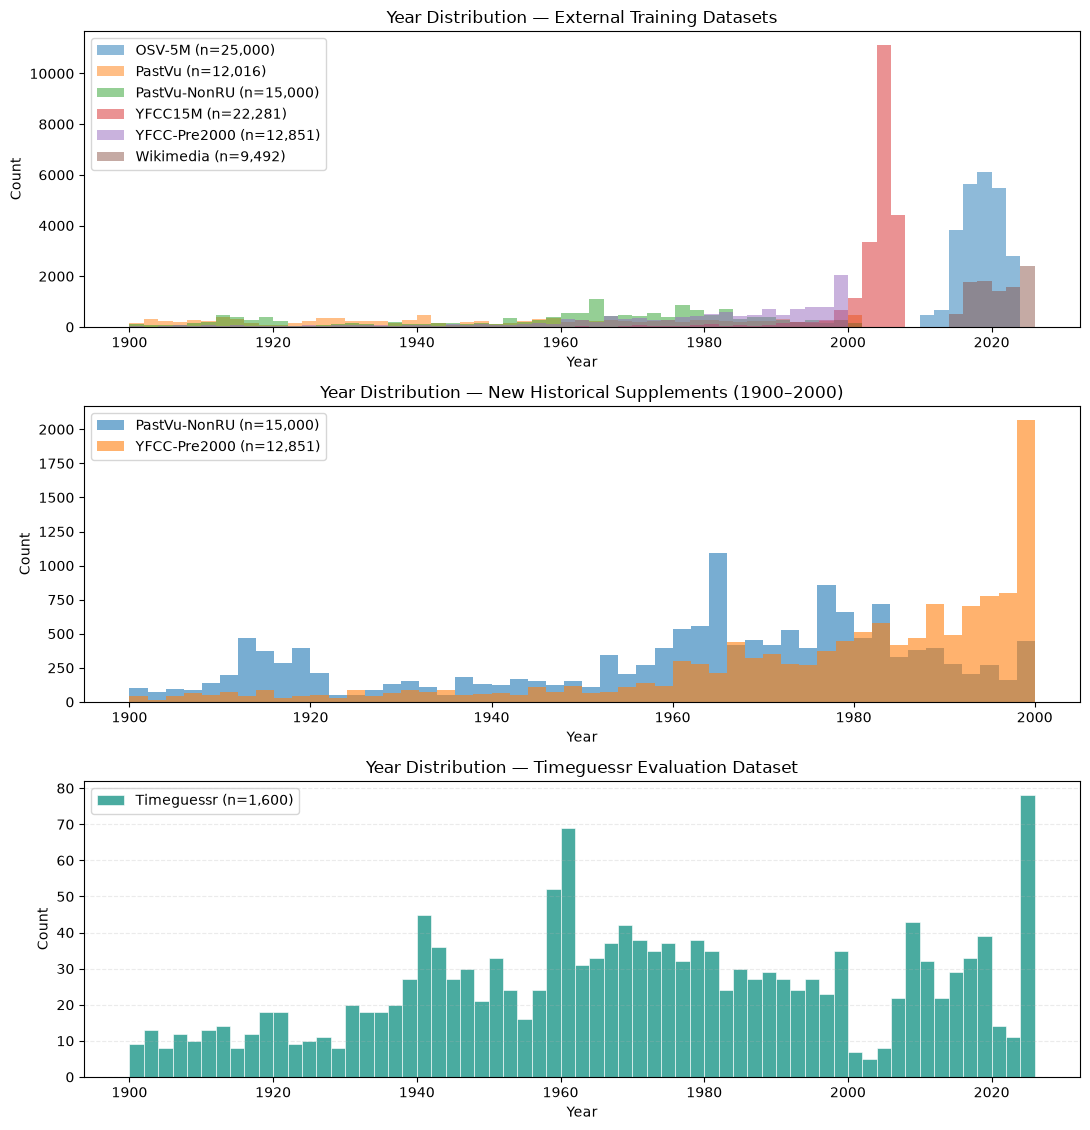

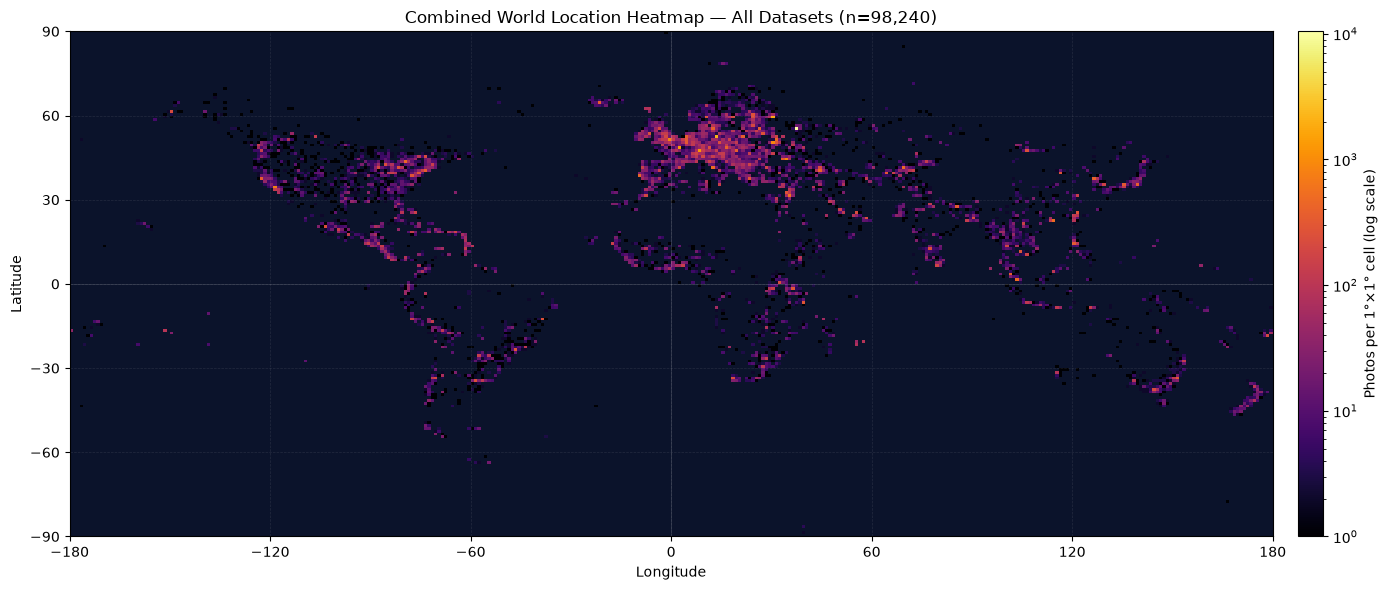

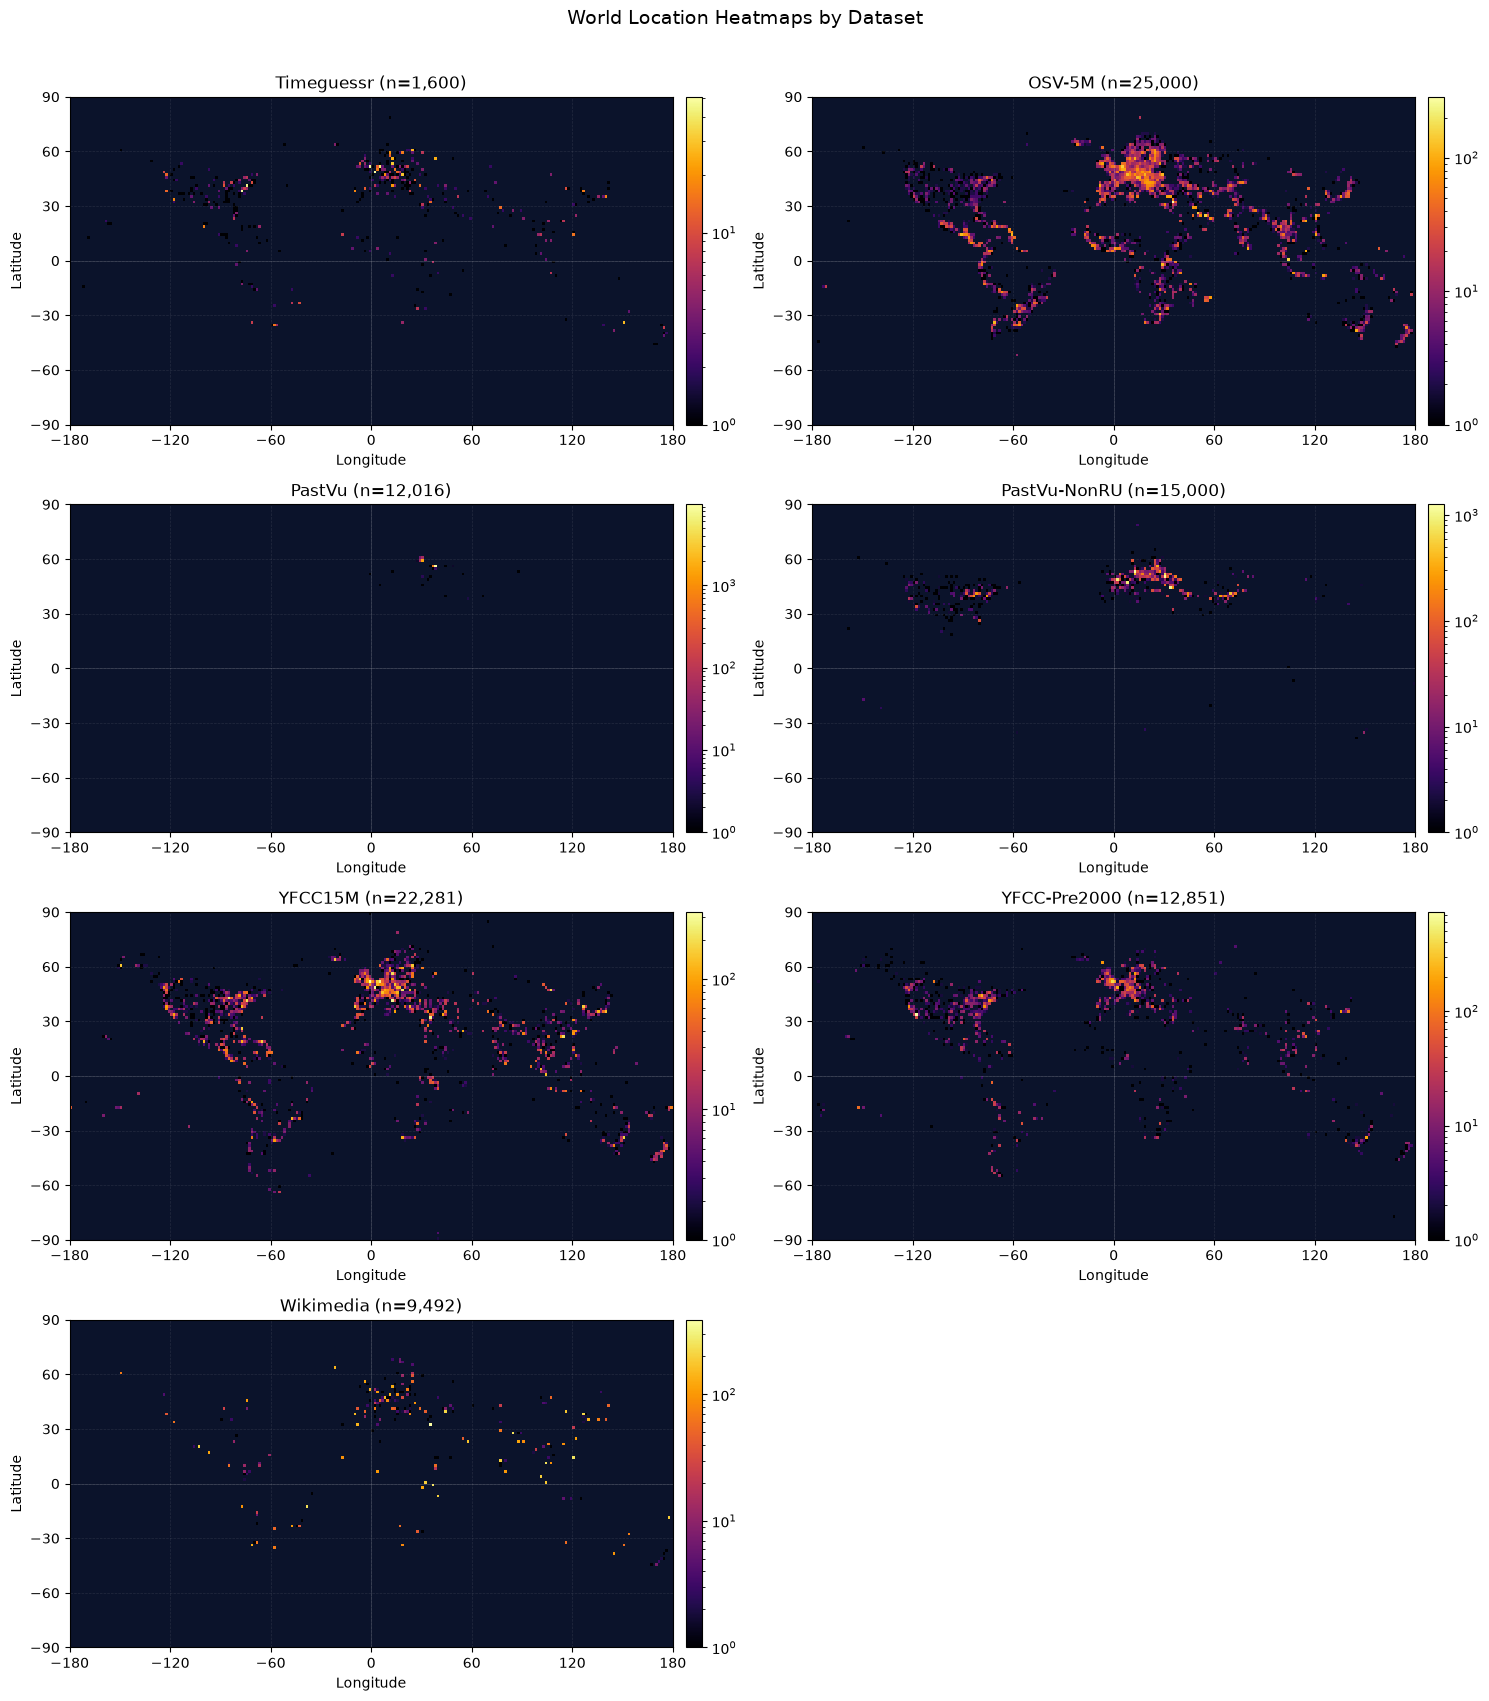

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

def load_local_timeguessr(base_dir: Path = TIMEGUESSR_DIR, save_csv: bool = True) -> pd.DataFrame:
    records = []
    if not base_dir.exists():
        return pd.DataFrame(columns=["image_path", "year", "latitude", "longitude", "source"])
    for img_path in sorted(base_dir.rglob("*")):
        if img_path.suffix.lower() not in (".jpg", ".jpeg", ".png", ".webp"):
            continue
        parts = img_path.stem.split("_")
        if len(parts) < 3:
            continue
        try:
            year = int(parts[0])
            lat = float(parts[1])
            lon = float(parts[2])
        except ValueError:
            continue
        records.append({
            "image_path": str(img_path.relative_to(PROJECT_ROOT)),
            "year": year,
            "latitude": lat,
            "longitude": lon,
            "source": "timeguessr",
        })
    df = pd.DataFrame(records)
    if save_csv and len(df) > 0:
        meta_path = base_dir / "metadata.csv"
        df.to_csv(meta_path, index=False)
        print(f"Saved {len(df):,} Timeguessr records to {meta_path}")
    return df

tg_df = load_local_timeguessr()
print(f"Local Timeguessr images: {len(tg_df):,}")

PASTVU_NON_RU_DIR = IMAGES_DIR / "pastvu_non_ru"
YFCC_PRE2000_DIR = IMAGES_DIR / "yfcc15m_pre2000"

dataset_specs = [
    ("OSV-5M", OSV5M_DIR / "metadata_balanced.csv"),
    ("PastVu", PASTVU_DIR / "metadata.csv"),
    ("PastVu-NonRU", PASTVU_NON_RU_DIR / "metadata.csv"),
    ("YFCC15M", YFCC_DIR / "metadata_downloaded.csv"),
    ("YFCC-Pre2000", YFCC_PRE2000_DIR / "metadata_downloaded.csv"),
    ("Wikimedia", WIKIMEDIA_DIR / "metadata_downloaded.csv"),
]

dfs = [("Timeguessr", tg_df)]
for name, csv_path in dataset_specs:
    if csv_path.exists():
        dfs.append((name, pd.read_csv(csv_path)))

for name, df in dfs:
    if len(df) > 0:
        extra = f" | countries={df['country'].nunique()}" if "country" in df.columns else ""
        print(f"{name:14s} | n={len(df):7,d} | years={int(df['year'].min())}-{int(df['year'].max())} | "
              f"lat=[{df['latitude'].min():.2f}, {df['latitude'].max():.2f}] | "
              f"lon=[{df['longitude'].min():.2f}, {df['longitude'].max():.2f}]{extra}")

# --- 1. Year Distributions (External Datasets, New Historical Supplements, and Timeguessr Separately) ---
non_empty = [(n, d) for n, d in dfs if len(d) > 0]
external_only = [(n, d) for n, d in non_empty if n != "Timeguessr"]
new_names = {"PastVu-NonRU", "YFCC-Pre2000"}
new_only = [(n, d) for n, d in non_empty if n in new_names]

if non_empty:
    panels = []
    if external_only:
        panels.append("external")
    if new_only:
        panels.append("new")
    if len(tg_df) > 0:
        panels.append("timeguessr")

    fig, axes = plt.subplots(len(panels), 1, figsize=(11, 3.8 * len(panels)), squeeze=False)

    for row_idx, panel in enumerate(panels):
        ax = axes[row_idx, 0]
        if panel == "external":
            for name, df in external_only:
                ax.hist(df["year"], bins=range(MIN_YEAR, MAX_YEAR + 2, 2), alpha=0.5, label=f"{name} (n={len(df):,})")
            ax.set_title("Year Distribution — External Training Datasets")
            ax.set_xlabel("Year")
            ax.set_ylabel("Count")
            ax.legend()
        elif panel == "new":
            for name, df in new_only:
                ax.hist(df["year"], bins=range(MIN_YEAR, 2002, 2), alpha=0.6, label=f"{name} (n={len(df):,})")
            ax.set_title("Year Distribution — New Historical Supplements (1900–2000)")
            ax.set_xlabel("Year")
            ax.set_ylabel("Count")
            ax.legend()
        elif panel == "timeguessr":
            ax.hist(
                tg_df["year"],
                bins=range(MIN_YEAR, MAX_YEAR + 2, 2),
                color="#2a9d8f",
                edgecolor="white",
                linewidth=0.5,
                alpha=0.85,
                label=f"Timeguessr (n={len(tg_df):,})",
            )
            ax.set_title("Year Distribution — Timeguessr Evaluation Dataset")
            ax.set_xlabel("Year")
            ax.set_ylabel("Count")
            ax.grid(axis="y", alpha=0.25, linestyle="--")
            ax.legend()

    plt.tight_layout()
    plt.show()

# --- 2. World Location Heatmaps (Combined + Per-Dataset) ---
def _plot_world_heatmap(ax, lons, lats, title: str, lon_bins: int = 360, lat_bins: int = 180):
    valid = np.isfinite(lons) & np.isfinite(lats) & (lons >= -180) & (lons <= 180) & (lats >= -90) & (lats <= 90)
    lons, lats = lons[valid], lats[valid]
    H, xedges, yedges = np.histogram2d(lons, lats, bins=[lon_bins, lat_bins], range=[[-180, 180], [-90, 90]])
    H_masked = np.ma.masked_where(H.T == 0, H.T)
    ax.set_facecolor("#0b132b")
    im = ax.imshow(
        H_masked,
        origin="lower",
        extent=[-180, 180, -90, 90],
        aspect="auto",
        cmap="inferno",
        norm=LogNorm(vmin=1, vmax=max(2, int(H.max()))),
        interpolation="nearest",
    )
    ax.axhline(0, color="white", alpha=0.15, linewidth=0.6)
    ax.axvline(0, color="white", alpha=0.15, linewidth=0.6)
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.set_xticks(range(-180, 181, 60))
    ax.set_yticks(range(-90, 91, 30))
    ax.grid(color="white", alpha=0.1, linestyle="--", linewidth=0.5)
    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    return im

if non_empty:
    # Combined world heatmap across all loaded datasets
    all_lons = np.concatenate([d["longitude"].to_numpy(dtype=float) for _, d in non_empty])
    all_lats = np.concatenate([d["latitude"].to_numpy(dtype=float) for _, d in non_empty])
    fig, ax = plt.subplots(figsize=(14, 6))
    im = _plot_world_heatmap(
        ax, all_lons, all_lats,
        f"Combined World Location Heatmap — All Datasets (n={len(all_lons):,})",
        lon_bins=360, lat_bins=180,
    )
    cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
    cbar.set_label("Photos per 1°×1° cell (log scale)")
    plt.tight_layout()
    plt.show()

    # Per-dataset world heatmaps for side-by-side geographic comparison
    ncols = 2
    nrows = int(np.ceil(len(non_empty) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.2 * nrows), squeeze=False)
    for idx, (name, df) in enumerate(non_empty):
        ax = axes[idx // ncols, idx % ncols]
        im = _plot_world_heatmap(
            ax,
            df["longitude"].to_numpy(dtype=float),
            df["latitude"].to_numpy(dtype=float),
            f"{name} (n={len(df):,})",
            lon_bins=240, lat_bins=120,
        )
        fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
    for idx in range(len(non_empty), nrows * ncols):
        axes[idx // ncols, idx % ncols].axis("off")
    plt.suptitle("World Location Heatmaps by Dataset", fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()